# 强制测量：纠缠熵与尺寸标度

读取同目录的 EA.csv、EB.csv、ΔE.csv；首行是 β，首列是 L。同一 L 重复出现时取最后一行，三个文件应来自同一套计算参数。只需 NumPy 和 Matplotlib。

下面依次显示 **1×3 总览图**、部分 β 的 **ΔS₂ = α ln L + c 拟合**、**α(β)**。L_MIN 控制拟合的最小尺寸，BETA_STEP 控制展示拟合图的 β 间隔；所有 β 都会参与拟合。

In [25]:
%matplotlib inline
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

DATA_DIR = next(p for base in (Path.cwd(), *Path.cwd().parents)
                for p in (base, base / "src/Measure/Force") if (p / "EA.csv").exists())
L_MIN = 3
BETA_STEP = 12
OUT = DATA_DIR / "figures"
OUT.mkdir(exist_ok=True)

def read_csv(name):
    raw = np.loadtxt(DATA_DIR / name, delimiter=",", ndmin=2)
    assert raw[0, 0] == 0 and np.isfinite(raw).all(), f"{name}: 表头或数值有误"
    rows = {row[0]: row[1:] for row in raw[1:]}  # 重复 L 取最后一行
    sizes = np.array(sorted(rows))
    assert np.all(sizes > 0) and np.all(sizes == sizes.astype(int)), "L 必须为正整数"
    return raw[0, 1:], sizes.astype(int), np.array([rows[L] for L in sizes])

loaded = [read_csv(name) for name in ("EA.csv", "EB.csv", "ΔE.csv")]
beta, L, SA = loaded[0]
assert np.all(np.diff(beta) > 0), "beta 必须递增"
assert all(np.array_equal(b, beta) and np.array_equal(s, L) for b, s, _ in loaded)
SB, DS = loaded[1][2], loaded[2][2]
assert np.allclose(DS, SA - SB, rtol=1e-9, atol=1e-10), "ΔE 与 EA - EB 不一致"
print(f"L = {L.tolist()}; beta = {beta[0]:g} … {beta[-1]:g} ({len(beta)} points)")

colors = ["#2166AC", "#D47719", "#7868A6", "#6F7E35", "#B34E7A"]
plt.rcParams.update({"font.size": 11, "figure.dpi": 120,
                     "axes.spines.top": False, "axes.spines.right": False})

def show_save(fig, name):
    for ext in ("png", "pdf"):
        fig.savefig(OUT / f"{name}.{ext}", dpi=200, bbox_inches="tight")
    plt.show()


L = [9, 18, 27, 36]; beta = 0.1 … 3 (59 points)


## 1×3 总览
同一 L 在三个面板中使用相同颜色和标记，A、B 共用纵轴范围。

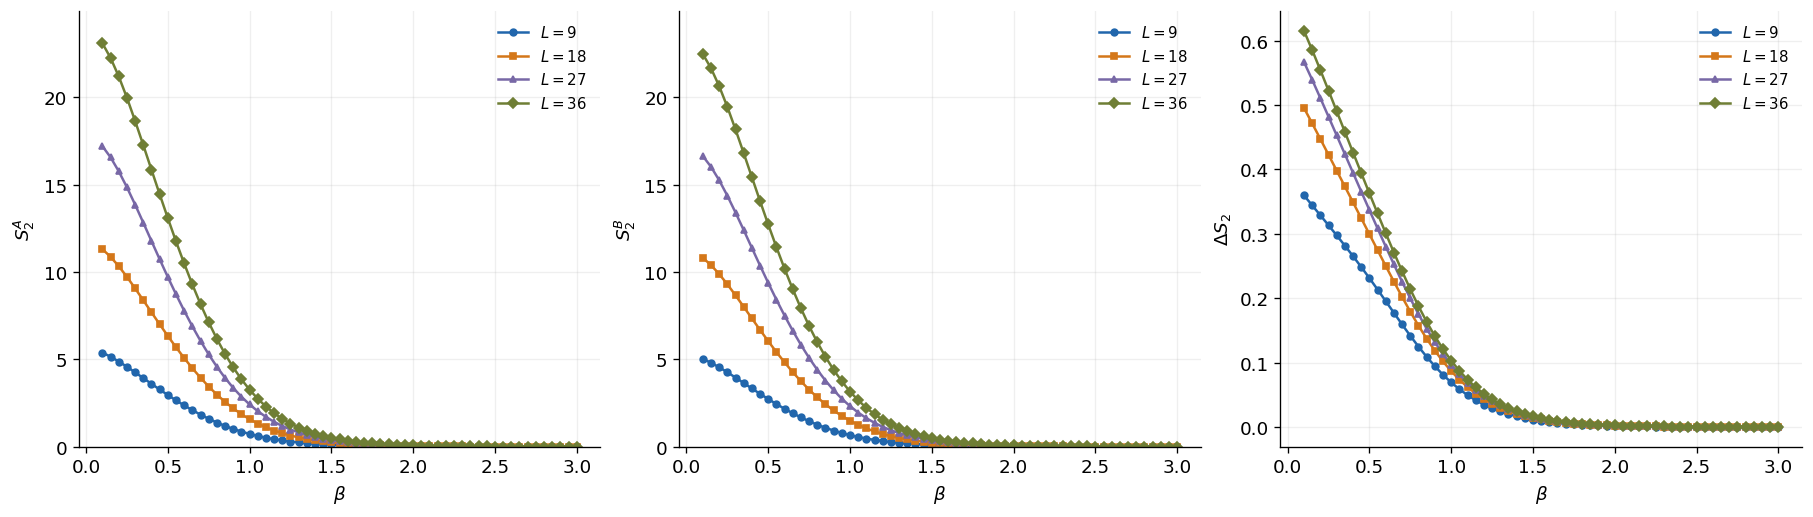

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), constrained_layout=True)
for ax, values, label in zip(axes, (SA, SB, DS),
                              (r"$S_2^A$", r"$S_2^B$", r"$\Delta S_2$")):
    for i, size in enumerate(L):
        ax.plot(beta, values[i], marker="os^DvPX"[i % 7], markersize=4,
                color=colors[i % 5], label=fr"$L={size}$")
    ax.set(xlabel=r"$\beta$", ylabel=label)
    ax.grid(alpha=0.2)
    ax.legend(frameon=False, fontsize=9)
limits = min(0, SA.min(), SB.min()), max(SA.max(), SB.max(), 1e-12) * 1.08
for ax in axes[:2]:
    ax.set_ylim(limits)
show_save(fig, "entropy_overview")


## 每个 β 的尺寸拟合

对选中的尺寸做等权最小二乘拟合：$\Delta S_2(L)=\alpha\ln L+c$。下图每隔 BETA_STEP 个 β 展示一次，并包含最后一个 β；**各面板独立缩放纵轴**。点是原始数据，线是拟合。

log_scaling_fit.csv 保存所有 β 的 α、c 和残差 RMSE。它们是有限尺寸拟合结果；可以增大 L_MIN 检查稳定性。强测量下接近机器精度的数据，其微小拟合系数没有可靠的物理意义。

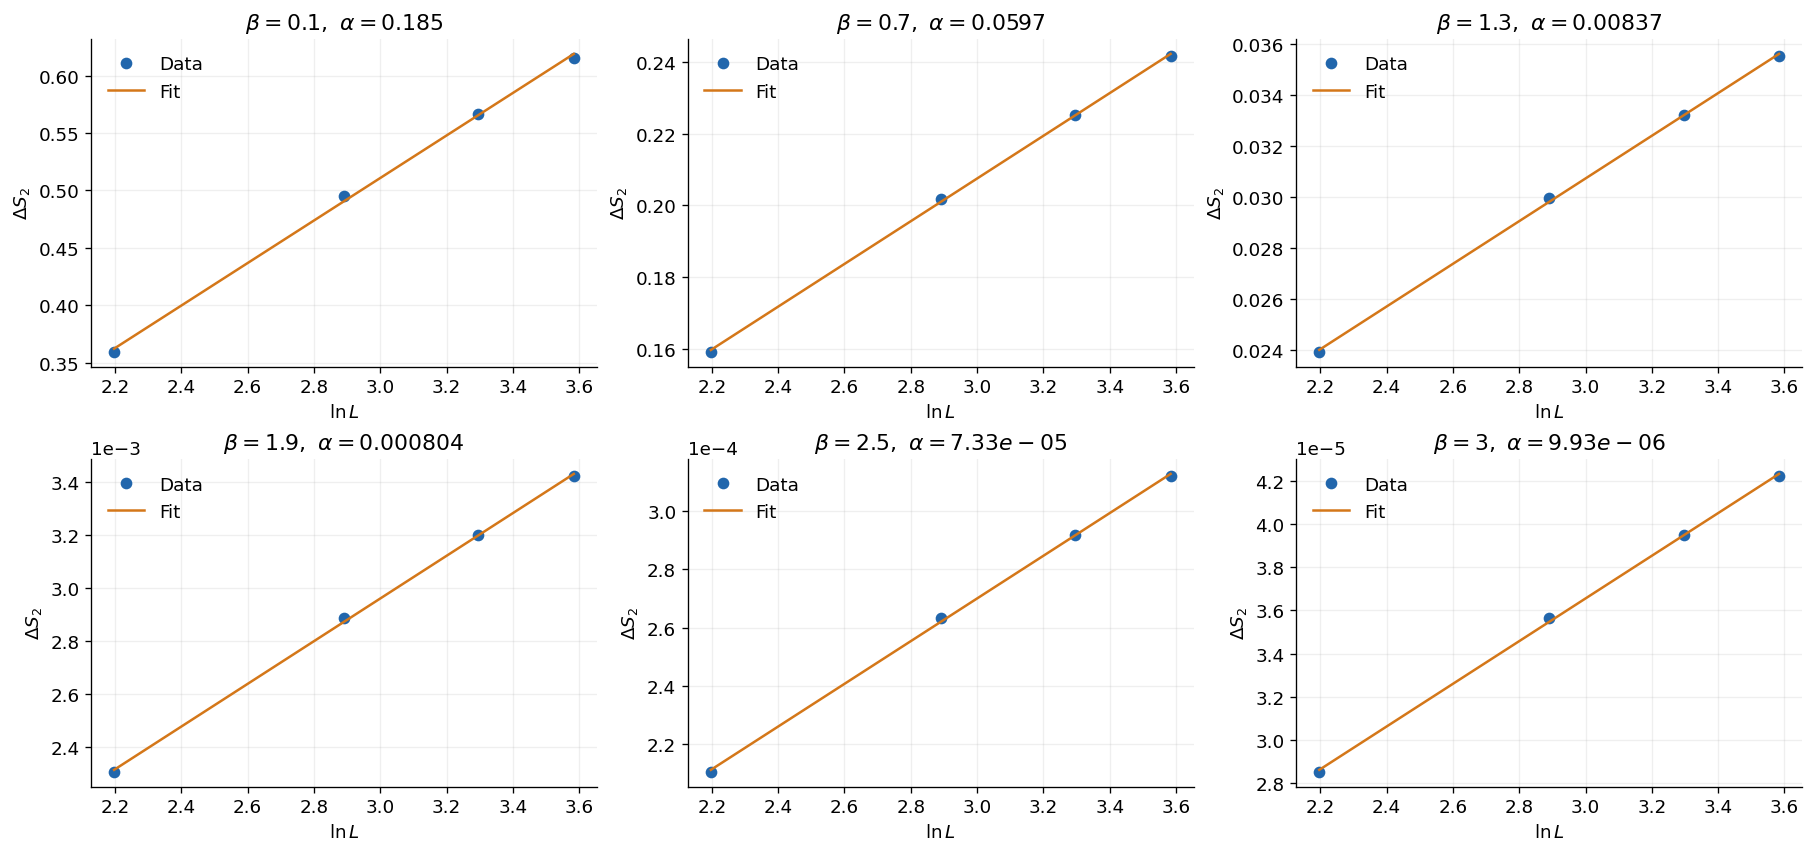

In [27]:
keep = L >= L_MIN
assert keep.sum() >= 2, "拟合至少需要两个不同尺寸"
assert BETA_STEP >= 1, "BETA_STEP 必须为正整数"
x, y = np.log(L[keep]), DS[keep]
alpha, c = np.polyfit(x, y, 1)  # 每一列对应一个 beta
rmse = np.sqrt(np.mean((y - (x[:, None] * alpha + c))**2, axis=0))
np.savetxt(OUT / "log_scaling_fit.csv", np.column_stack((beta, alpha, c, rmse)),
           delimiter=",", header="beta,alpha,c,rmse", comments="")

chosen = np.unique(np.r_[np.arange(0, len(beta), BETA_STEP), len(beta) - 1])
ncols = min(3, len(chosen))
fig, axes = plt.subplots(int(np.ceil(len(chosen) / ncols)), ncols, squeeze=False,
                         figsize=(5 * ncols, 3.5 * int(np.ceil(len(chosen) / ncols))),
                         constrained_layout=True)
xx = np.linspace(x.min(), x.max(), 100)
for ax, j in zip(axes.flat, chosen):
    ax.plot(x, y[:, j], "o", color=colors[0], label="Data")
    ax.plot(xx, alpha[j] * xx + c[j], "-", color=colors[1], label="Fit")
    ax.set(xlabel=r"$\ln L$", ylabel=r"$\Delta S_2$",
           title=fr"$\beta={beta[j]:g},\ \alpha={alpha[j]:.3g}$")
    ax.ticklabel_format(axis="y", style="sci", scilimits=(-3, 3), useOffset=False)
    ax.grid(alpha=0.2)
    ax.legend(frameon=False)
for ax in list(axes.flat)[len(chosen):]:
    ax.set_visible(False)
show_save(fig, "log_scaling_examples")


## $\alpha$ 随 $\beta$ 的变化

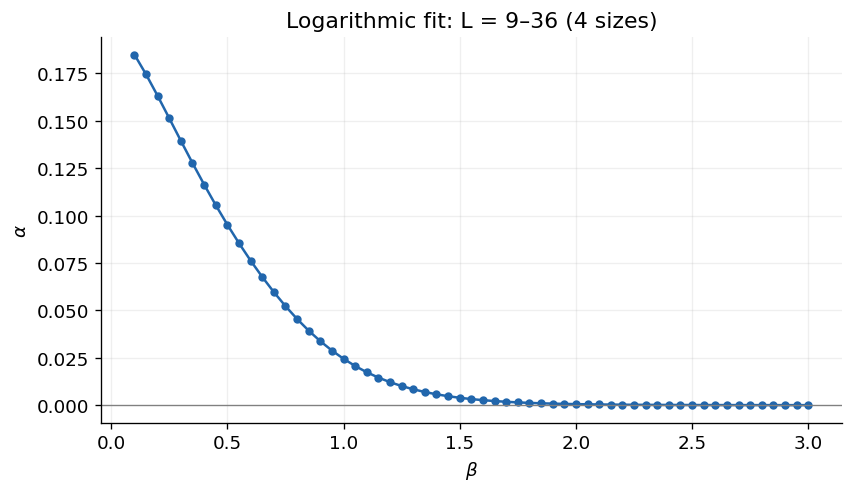

In [28]:
fig, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)
ax.plot(beta, alpha, "o-", color=colors[0], markersize=4)
ax.axhline(0, color="0.5", linewidth=0.8)
ax.set(xlabel=r"$\beta$", ylabel=r"$\alpha$",
       title=f"Logarithmic fit: L = {L[keep].min()}–{L[keep].max()} ({keep.sum()} sizes)")
ax.grid(alpha=0.2)
show_save(fig, "alpha_vs_beta")
